In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load dataset
df = pd.read_csv(r"C:\Users\purva\OneDrive\Desktop\lp3\dataset\sales_data_sample.csv", encoding="latin1")

print("Dataset Shape:", df.shape)
print(df.head())

# Select numerical features
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

# Handle missing values
X = X.fillna(X.mean())

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Dataset Shape: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue

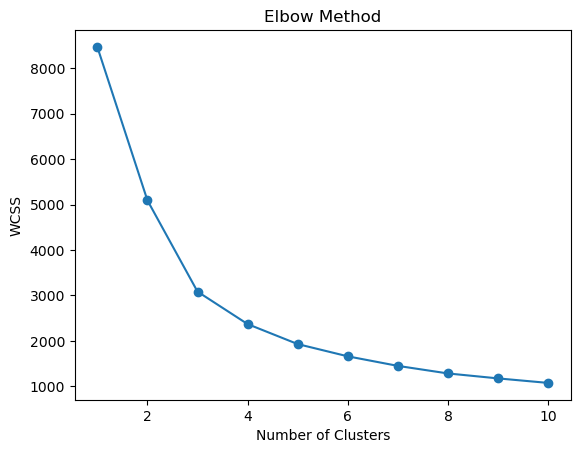

In [2]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

Cluster assignments:
   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        1
4               49     100.00  5205.27        1

Number of records in each cluster:
Cluster
2    1035
1     907
0     881
Name: count, dtype: int64


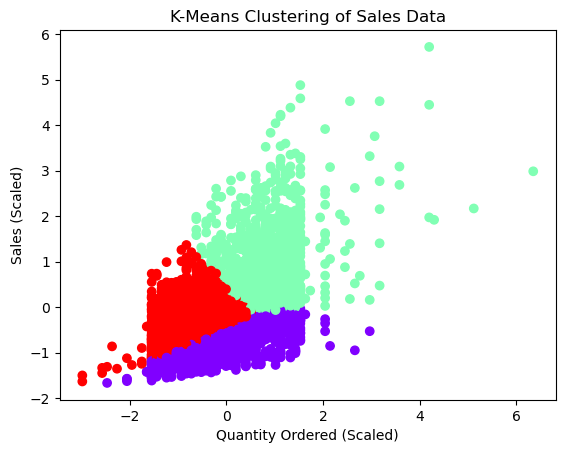

In [3]:
# Select optimal number of clusters from elbow graph
k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster assignments:")
print(df[["QUANTITYORDERED", "PRICEEACH", "SALES", "Cluster"]].head())

print("\nNumber of records in each cluster:")
print(df["Cluster"].value_counts())

# Visualize clusters
plt.scatter(X_scaled[:, 0], X_scaled[:, 2],
            c=df["Cluster"], cmap="rainbow")

plt.title("K-Means Clustering of Sales Data")
plt.xlabel("Quantity Ordered (Scaled)")
plt.ylabel("Sales (Scaled)")
plt.show()